# Sociophysical Models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from math import sqrt

from sklearnex import patch_sklearn
patch_sklearn()

import os
os.environ["SKLEARNEX_VERBOSE"] = "INFO"

from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import shap

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


## Data

In [2]:
# Mapping dictionary
mapping_dict = {'Arid': 0, 'Snow': 1, 'Temperate': 2, 'Tropical': 3}

In [3]:
old_cols = ['BSA', 'NDBI', 'NDVI', 'DEM']
new_cols = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM']

In [4]:
# SUE dataset
data_sue                 = pd.read_csv('data/data_sue.csv')
data_sue['Coastal?']     = data_sue['Coastal?'].fillna(False).astype(int)
data_sue['Climate Zone'] = data_sue['Climate Zone'].map(mapping_dict)
data_sue.rename(columns=dict(zip(old_cols, new_cols)), inplace=True)

In [5]:
# NTL dataset
data_ntl                 = pd.read_csv('data/data_ntl.csv')
data_ntl['Coastal?']     = data_ntl['Coastal?'].astype(int)
data_ntl['Climate Zone'] = data_ntl['Climate Zone'].map(mapping_dict)
data_ntl.rename(columns=dict(zip(old_cols, new_cols)), inplace=True)

In [6]:
features = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM', 'Coastal?', 'Climate Zone', 
            'Black Percentile', 'Hispanic Percentile', 'White Percentile', 'Median Income Percentile']
label    = 'SUHI'

In [7]:
def get_data(df):
    df = df[features+[label]].dropna().copy()
    X  = df[features]
    y  = df[label]
    return X, y

In [8]:
X_sue, y_sue = get_data(data_sue)
X_ntl, y_ntl = get_data(data_ntl)

## Models

### XGBoost

In [9]:
model_sue = XGBRegressor(n_estimators=150, max_depth=15, importance_type='gain', random_state=1, 
                         tree_method='hist', grow_policy = 'lossguide')
model_sue.fit(X_sue, y_sue)
model_sue.score(X_sue, y_sue)

0.9999922118948601

In [10]:
model_ntl = XGBRegressor(n_estimators=150, max_depth=15, importance_type='gain', random_state=1, 
                         tree_method='hist', grow_policy = 'lossguide')
model_ntl.fit(X_ntl, y_ntl)
model_ntl.score(X_ntl, y_ntl)

0.9999949834988584

## SHAP Values

In [11]:
def get_shap(model, X):
    explainer = shap.TreeExplainer(model, approximate=True)
    shap_values = explainer(X)
    
    shap_df = pd.DataFrame(
    np.c_[shap_values.base_values, shap_values.values],
    columns = ["bv"] + list(X.columns)
    )
    
    temp_df = pd.read_csv('data/data.csv').dropna(subset=['BSA', 'NDBI', 'NDVI', 'DEM', 'Climate Zone', 'Coastal?', 'SUHI'])
    
    #old_cols = ['BSA', 'NDBI', 'NDVI', 'DEM', 'Climate Zone', 'Coastal?']
    #new_cols = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM', 'ClimateZone', 'Coastal']
    
    temp_df.rename(columns={'Climate Zone': 'ClimateZone', 'Coastal?': 'Coastal'}, inplace=True)
    
    cols1 = ['GEOID', 'Area', 'Is low income?', 'Below Poverty', 'Black', 'Hispanic', 'White', 'Urban_name', 'ClimateZone', 'Coastal']
    for col in cols1:
        shap_df[col] = temp_df[col]
    return shap_df

In [12]:
shap_df_sue = get_shap(model_sue, X_sue)
shap_df_ntl = get_shap(model_ntl, X_ntl)

In [13]:
shap_df_sue.head()

,bv,ΔBSA,ΔNDBI,ΔNDVI,ΔDEM,Coastal?,Climate Zone,Black Percentile,Hispanic Percentile,White Percentile,Median Income Percentile,GEOID,Area,Is low income?,Below Poverty,Black,Hispanic,White,Urban_name,ClimateZone,Coastal
0,3.323077,0.033801,1.223876,-2.696601,0.015304,0.019471,0.382931,-0.296186,-0.039609,0.099778,-0.177604,8.001008e+09,6.443751e+05,True,27.0,19.145907,38.695136,9.713184,"Denver--Aurora, CO",Arid,False
1,3.323077,-0.044088,-0.354144,-2.566099,-0.339069,0.035223,0.172862,-0.138525,0.043379,-0.113265,0.095529,8.001008e+09,6.366555e+05,True,29.0,22.761449,51.765778,8.329401,"Denver--Aurora, CO",Arid,False
2,3.323077,0.213996,-0.023166,-1.014077,-0.656195,0.053004,0.093764,0.061317,0.015017,0.336707,-0.036808,8.001008e+09,1.639900e+06,True,12.0,17.167229,55.358095,14.677619,"Denver--Aurora, CO",Arid,False
3,3.323077,0.057968,0.285904,-2.401414,0.044171,0.026340,0.230966,0.160249,0.056227,0.155154,-0.017725,8.001008e+09,1.952210e+06,True,19.0,13.148848,52.921966,29.656572,"Denver--Aurora, CO",Arid,False
4,3.323077,0.117282,0.478112,-0.991489,-0.474483,0.058861,0.088732,-0.016347,0.012321,0.192563,-0.029497,8.001008e+09,2.700551e+06,False,28.0,3.875476,27.255400,63.217310,"Denver--Aurora, CO",Arid,False


## SHAP Feature Importance

In [14]:
# Save SHAP values for test set
def explain_model(model_xgb, X_test, y_test, filename):
    
    if filename == 'SUE':
        titles = ['1(a) Feature Importance - SUE', '1(b) Feature Effect - SUE']
    if filename == 'NTL':
        titles = ['2(a) Feature Importance - NTL', '2(b) Feature Effect - NTL']
    
    # Compute SHAP values for test set
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), dpi=1000)
    # SHAP
    explainer = shap.TreeExplainer(model_xgb, approximate=True)
    shap_values = explainer(X_test)
    # Create a SHAP bar and beeswarm plot
    plt.sca(ax1)
    shap.plots.bar(shap_values, max_display=10, show=False)
    ax1.set_title(titles[0])
    plt.sca(ax2)
    shap.plots.beeswarm(shap_values, max_display=10, show=False)
    ax2.tick_params(axis='y', which='both', left=False, labelleft=False)
    ax2.set_xlabel('SHAP value')
    ax2.set_title(titles[1])
    plt.subplots_adjust(wspace = 0.1)
    fig.set_size_inches(10, 5)
    font = {'size': 14}
    plt.rc('font', **font)
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["Verdana"]

    plt.savefig('graphs/shap/feature_importance_sociophysical_{}.svg'.format(filename), bbox_inches='tight', dpi=1000)




In [15]:
explain_model(model_sue, X_sue, y_sue, filename='SUE')



In [16]:
explain_model(model_sue, X_sue, y_sue, filename='SUE')



In [17]:
explain_model(model_ntl, X_ntl, y_ntl, filename='NTL')

## SHAP PDP

In [18]:
def shap_pdp(model_xgb, X_test, y_test, filename):
    demo_features = ['Black Percentile', 'Hispanic Percentile', 'White Percentile', 'Median Income Percentile']
    
    for j in range(4):
        shap.plots.partial_dependence(demo_features[j], 
                                      model_xgb.predict, 
                                      X_test[features], 
                                      model_expected_value=True, 
                                      feature_expected_value=True, 
                                      ice=False, 
                                      show=False)
        font = {'size': 16}
        plt.rc('font', **font)
        plt.rcParams["font.family"] = "sans-serif"
        plt.rcParams["font.sans-serif"] = ["Verdana"]
        plt.savefig('graphs/pdp/pdp_sociophysical_{}_{}.svg'.format(demo_features[j], filename), bbox_inches='tight', dpi=1000)
            

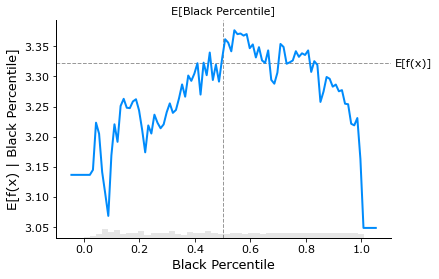

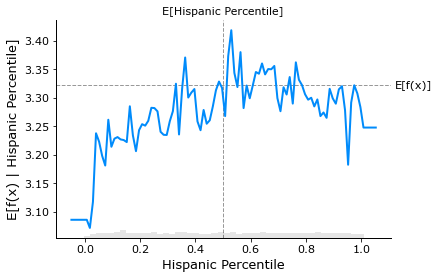

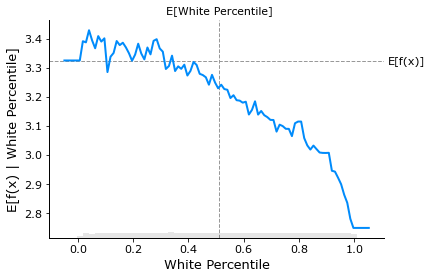

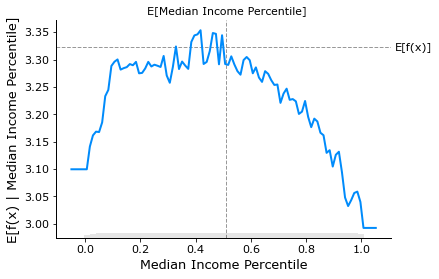

In [19]:
shap_pdp(model_sue, X_sue, y_sue, filename='SUE')

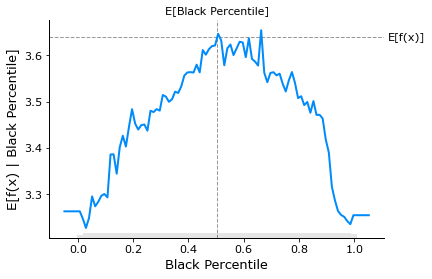

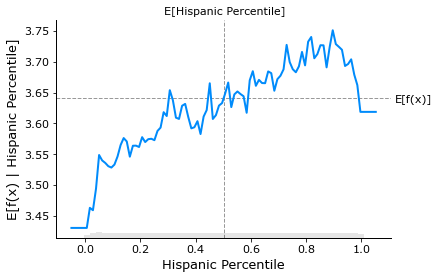

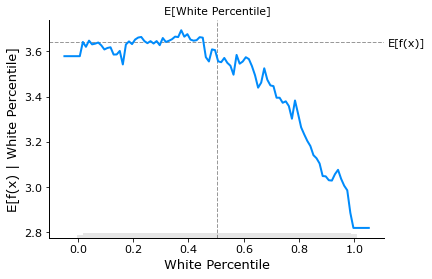

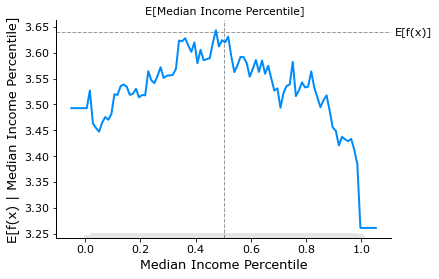

In [20]:
shap_pdp(model_ntl, X_ntl, y_ntl, filename='NTL')

## SHAP Interaction Plots for Sociophysical Interactions

In [27]:
def shap_scatter_sociophysical(model_xgb, X_test, y_test, filename):
    explainer = shap.TreeExplainer(model_xgb, approximate=True)
    shap_values = explainer(X_test)
    
    refs = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)', '(i)', '(j)', '(l)', '(m)', '(n)', '(o)', '(p)']
    phys = ['\u0394NDVI', '\u0394NDBI', '\u0394DEM', '\u0394BSA']
    demo = ['Median Income Percentile', 'Black Percentile', 'Hispanic Percentile', 'White Percentile']
    fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(14,14), constrained_layout=True)
    idx=0
    for i in range(4):
        for j in range(4):
            shap.plots.scatter(shap_values[:, phys[i]], color=shap_values[:, demo[j]], show=False, ax=axes[i,j])
            if j > 0:
                axes[i,j].set(ylabel=None) # turn off y axis since it's redundant
            ax.text(0.01, 1.05, refs[idx], transform=ax.transAxes, fontsize=12, va='top', ha='left')
            idx+=1

    plt.savefig('graphs/shap_interaction/shap_scatter_sociophysical_{}.svg'.format(filename), bbox_inches='tight', dpi=1000)
    plt.savefig('graphs/shap_interaction/shap_scatter_sociophysical_{}.jpg'.format(filename), bbox_inches='tight', dpi=1000)

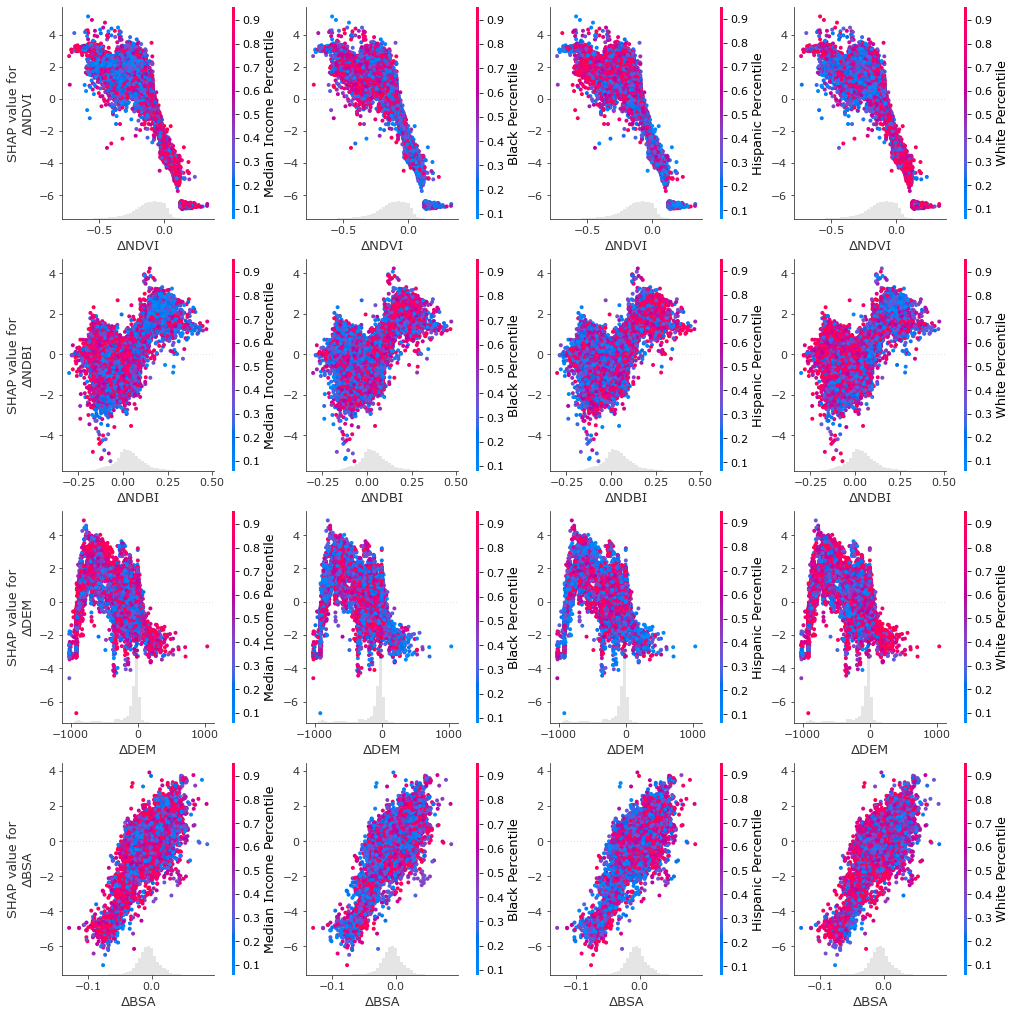

In [28]:
shap_scatter_sociophysical(model_sue, X_sue, y_sue, filename='SUE')


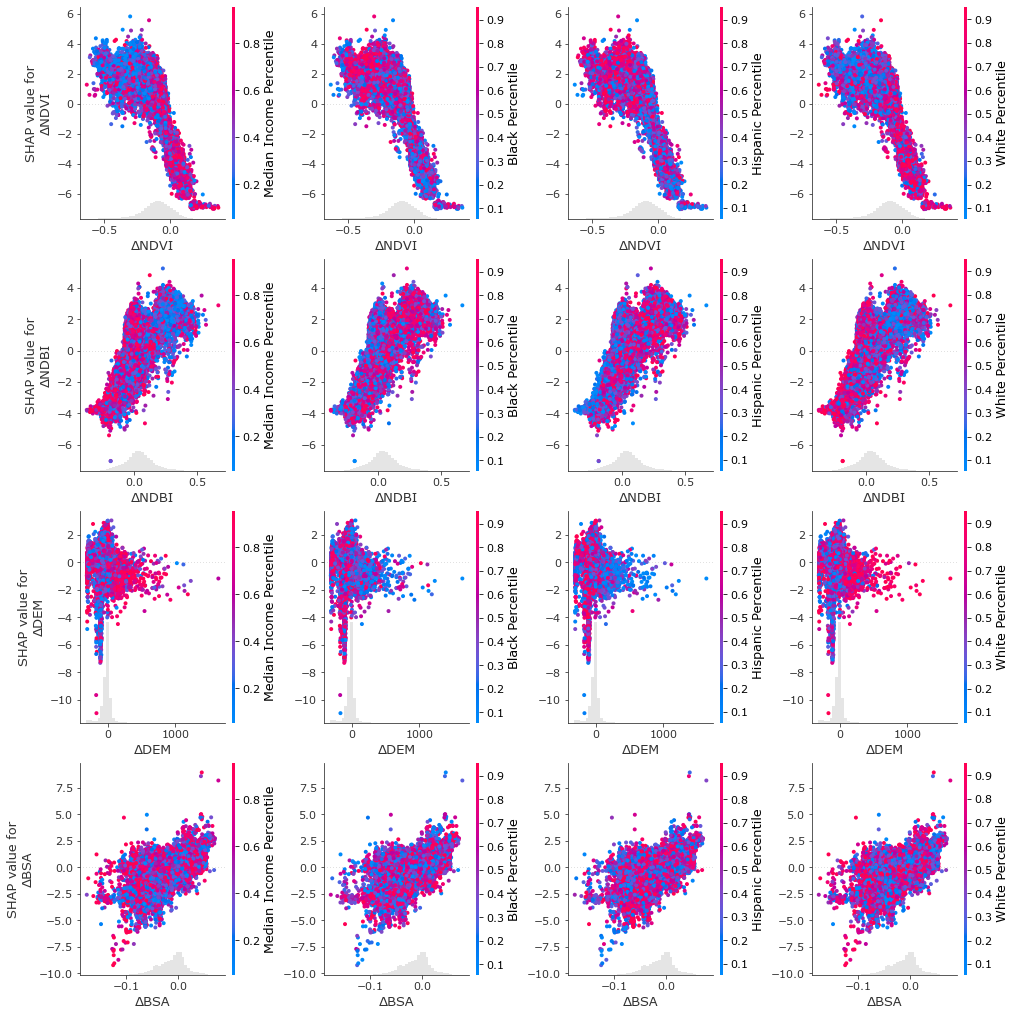

In [29]:
shap_scatter_sociophysical(model_ntl, X_ntl, y_ntl, filename='NTL')
